**Week 4**

Exploratory Data Analysis (EDA)
Objective: To analyze housing data using statistical methods and visualizations to understand the factors affecting house prices.

First, libraries import pannu.

Cell 1 — Import Libraries

### Import Libraries

**Purpose:** Import the analysis libraries and set the seaborn whitegrid theme for clean charts.

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

**Insight:** Charts in this week share one consistent style.

Cell 2 — Load Cleaned Dataset

### Load the Cleaned Dataset

**Purpose:** Load `housing_cleaned.csv` and preview it.

In [42]:
df = pd.read_csv("housing_cleaned.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (4600, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-06-13 00:00:00,385000.0,3.0,2.25,1920.0,4833.0,1.0,0.0,0.0,4.0,1060.0,860.0,1921.0,0.0,10559 Evanston Ave N,Seattle,WA 98133,USA
1,2014-05-02 00:00:00,462000.0,4.0,2.50,2820.0,8408.0,2.0,0.0,0.0,3.0,2820.0,0.0,1975.0,0.0,17052 4th Ave NE,Shoreline,WA 98155,USA
2,2014-06-30 00:00:00,1309500.0,4.0,2.50,2680.0,12215.0,1.0,1.0,4.0,3.0,1590.0,1090.0,1956.0,2001.0,18051 Normandy Terrace SW,Normandy Park,WA 98166,USA
3,2014-07-08 00:00:00,415000.0,4.0,1.75,1920.0,7700.0,2.0,0.0,0.0,4.0,1920.0,0.0,1970.0,0.0,7209 SE 70th St,Newcastle,WA 98056,USA
4,2014-06-24 00:00:00,725000.0,4.0,2.50,2650.0,18295.0,2.0,0.0,0.0,3.0,2650.0,0.0,1986.0,0.0,211 140th Ave SE,Bellevue,WA 98005,USA


**Insight:** The cleaned data has **4,600 rows and 18 columns**. Row 2 now shows `price = 462,000`, the median filled in for the earlier missing value.

Cell 3 — House Price Distribution
Price distribution eppadi irukku nu histogram-la paakkalaam.

### House Price Distribution

**Purpose:** Plot a histogram with a KDE curve to see how house prices are distributed.

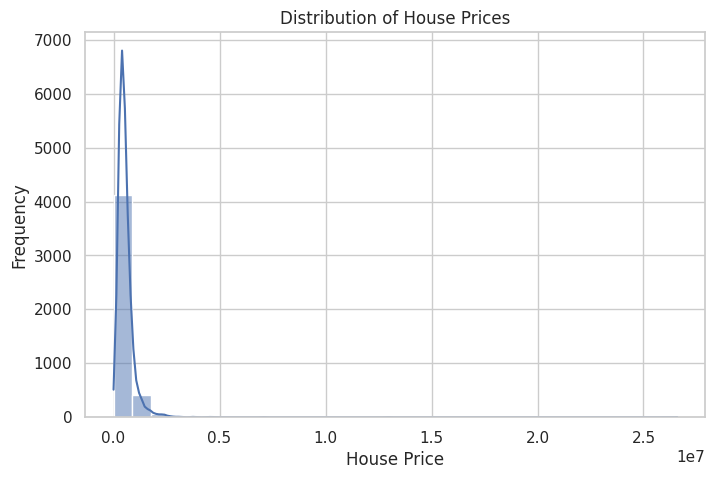

In [43]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="price", bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.show()

**Insight:** The distribution is strongly **right-skewed**: most houses cost below about 1M, while a few go up to 26.6M. The average (about 550K) is pulled above the median (about 462K) by these expensive houses.

Cell 4 — Living Area vs House Price
Living area increase aagumbodhu price eppadi change aagudhu nu analyze pannalaam.

### Living Area vs House Price

**Purpose:** Use a scatter plot to see how price changes when living area increases.

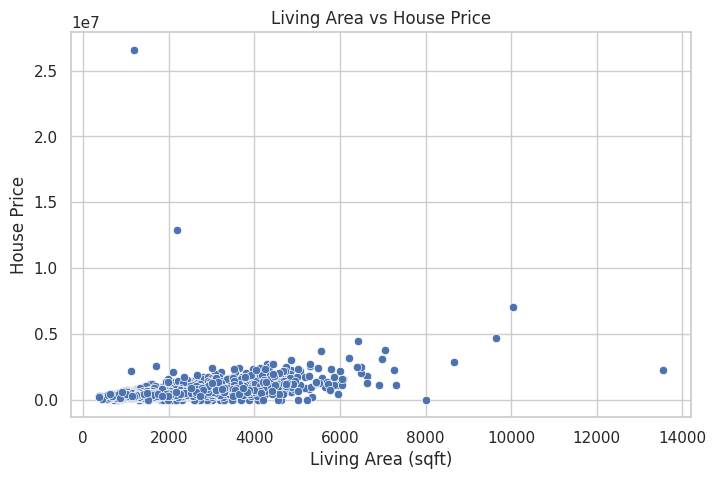

In [44]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="sqft_living", y="price")

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.show()

**Insight:** There is a **positive trend**: bigger houses generally cost more. Two points (about 26.6M at roughly 1,200 sqft and about 12.9M at roughly 2,200 sqft) are extreme anomalies, and one large house of about 8,000 sqft has a price near 0, which is invalid data.

Cell 5 — Bedrooms vs House Price

### Bedrooms vs House Price

**Purpose:** Use boxplots to compare the price range for each number of bedrooms.

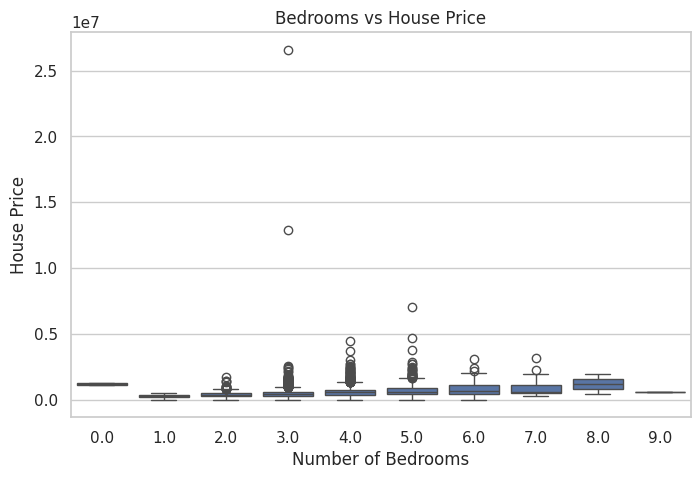

In [45]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="bedrooms", y="price")

plt.title("Bedrooms vs House Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("House Price")
plt.show()

**Insight:** The median price rises slowly as bedrooms increase up to 8, but the ranges overlap heavily, so bedrooms alone are a weak price indicator. The 3-bedroom group holds the two extreme price outliers, and a 0-bedroom house priced at about 1.2M looks like a data error.

Cell 6 — Correlation Heatmap
Numerical features-ku idaiyila irukkura relationship-a identify pannalaam.

### Correlation Heatmap

**Purpose:** Show the correlation between all numerical features, including price.

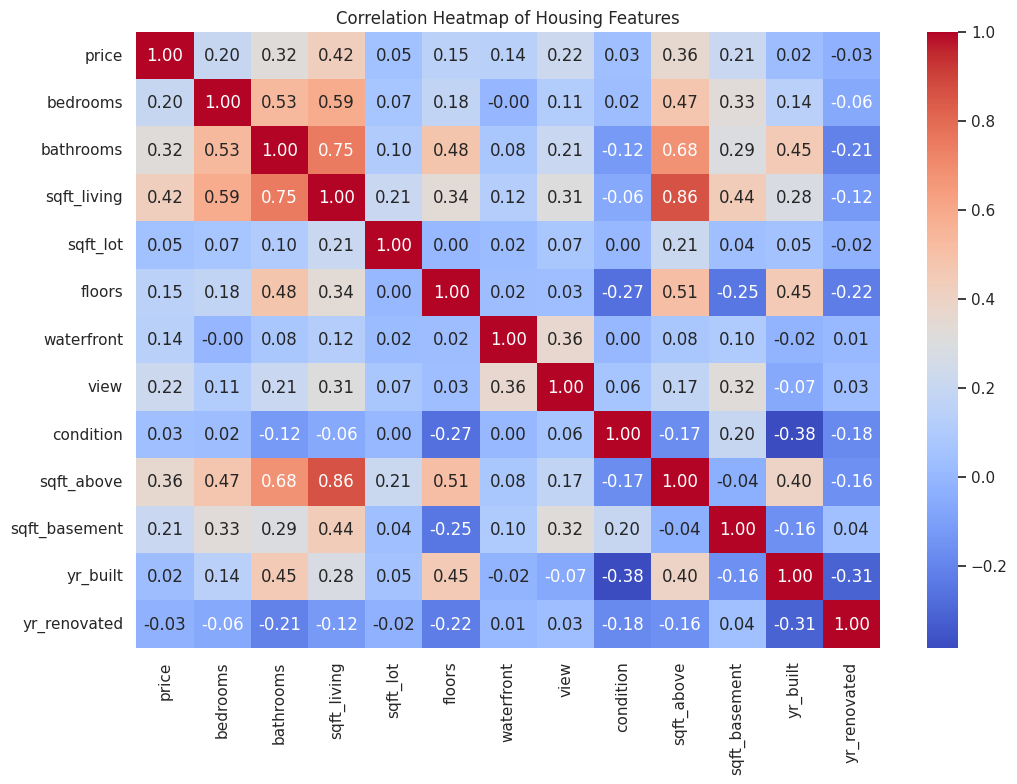

In [46]:
num_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    num_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Housing Features")
plt.show()

**Insight:** The features most related to price are `sqft_living` (**0.42**), `sqft_above` (0.36) and `bathrooms` (0.32). `sqft_lot`, `condition` and `yr_built` are almost unrelated (0.02 to 0.05). Several features are strongly related to each other (`sqft_living` and `sqft_above` 0.86, `sqft_living` and `bathrooms` 0.75), which is multicollinearity to watch for in modelling. Correlations with price are modest partly because of the extreme price outliers.

Cell 7 — Average Price by City

### Average Price by City

**Purpose:** Group the data by city and plot the 10 cities with the highest average price.

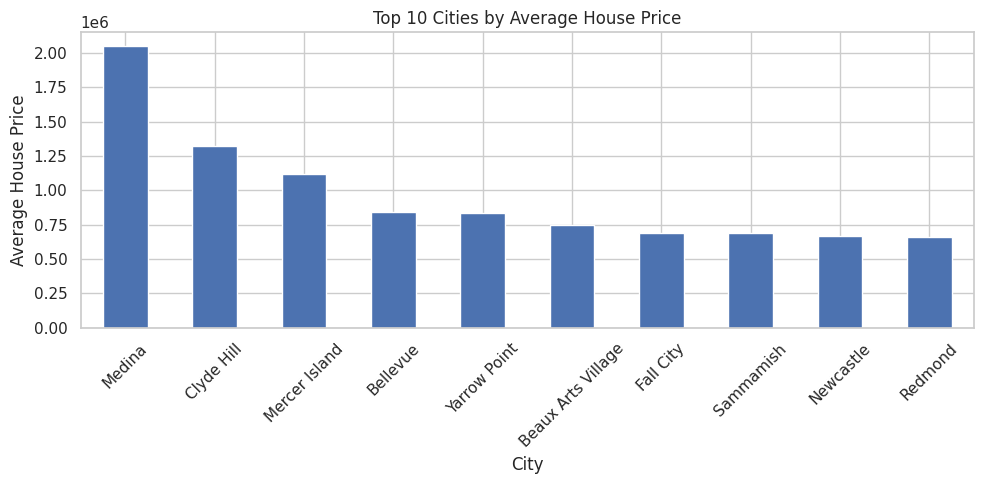

In [47]:
if "city" in df.columns:
    city_prices = (
        df.groupby("city")["price"]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    city_prices.plot(kind="bar", figsize=(10, 5))
    plt.title("Top 10 Cities by Average House Price")
    plt.xlabel("City")
    plt.ylabel("Average House Price")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Insight:** **Medina** is the most expensive city (about 2.05M), followed by **Clyde Hill** (about 1.3M) and **Mercer Island** (about 1.1M). Even the 10th city, Redmond, is about 0.66M. The top city costs roughly 3 to 4 times the dataset average, so **location has a big influence on price**.

Cell 8 — Statistical Summary

### Statistical Summary of the Cleaned Data

**Purpose:** Review the final statistics of every numerical feature after cleaning.

In [48]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.503548e+05,3.390000,2.165652,2134.646739,1.477990e+04,1.513043,0.007174,0.237391,3.442826,1825.060652,305.731522,1970.754783,794.273478
std,5.615620e+05,0.900622,0.776436,955.682074,3.585285e+04,0.532631,0.084404,0.773384,0.673959,856.654559,460.679438,29.445545,976.516282
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.250000e+05,3.000000,1.750000,1470.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,1200.000000,0.000000,1951.000000,0.000000
50%,4.620000e+05,3.000000,2.250000,1970.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1975.000000,0.000000
75%,6.500000e+05,4.000000,2.500000,2600.000000,1.084225e+04,2.000000,0.000000,0.000000,4.000000,2290.000000,600.000000,1996.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


**Insight:** Price has mean about 550K and standard deviation about 562K, which shows a very high spread. The minimum price is still 0 and the maximum is 26.59M, so invalid and extreme prices should be treated before modelling.

### Week 4 Conclusion

Key findings from the EDA:

- House prices are strongly right-skewed with a few extreme values.
- Living area (`sqft_living`, correlation 0.42) is the strongest numerical factor affecting price, followed by `sqft_above` and `bathrooms`.
- Location matters a lot: Medina, Clyde Hill and Mercer Island have the highest average prices.
- Area and bathroom features are highly correlated with each other.
- Invalid values (price = 0, bedrooms = 0) and extreme prices need treatment before modelling.

The next stage will focus on treating these outliers and building on these findings.